# SET-4: Automated MLOps Pipeline for Telco Customer Churn Prediction
### **Algorithm: Support Vector Machine (SVM) | Target: Binary Churn Prediction**
---

## 📌 Experiment Objectives (Sub-questions a through f)
This notebook implements an automated, production-grade MLOps pipeline on the **Telco Customer Churn** dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`) covering:

1. **Sub-question (a): Data Preprocessing & Cleaning**
   - Convert `TotalCharges` to numeric, impute missing values (median).
   - Remove duplicate customer records based on `customerID`.
   - Encode categorical variables (One-Hot & Binary encoding).
   - Apply `StandardScaler` to numerical features.
2. **Sub-question (b): Feature Engineering, Selection & SVM Modeling**
   - Engineer domain feature: `Avg_Monthly_Charge_Ratio = TotalCharges / (tenure * MonthlyCharges)`.
   - Perform **Pearson correlation-based** feature selection.
   - Perform **LASSO (L1 regularization)** feature selection.
   - Train an SVM Classifier with hyperparameter tuning ($C$ and `kernel`: linear vs. RBF).
   - Report comprehensive metrics: **Accuracy, Precision, Recall, F1-Score, and ROC-AUC**.
   - Plot Confusion Matrix and ROC Curves.
3. **Sub-question (c): Artifact & Dataset Versioning (Git & DVC)**
   - Track dataset artifacts across distinct versions ($v1$ and $v2$) using **DVC** and local remote storage.
   - Demonstrate version switching ($v1.0 \leftrightarrow v2.0$) and reproducibility via DVC checkout.
4. **Sub-question (d): Experiment Tracking & Model Registry (MLflow)**
   - Log hyperparameters, metrics, and serialized model artifacts for every run.
   - Compare experiment iterations in MLflow.
   - Register model in MLflow Model Registry and promote the winning version to **Production**.
5. **Sub-question (e): Modular Architecture Orchestration (`main.py`)**
   - Automate complete workflow inside modular Python scripts under `src/`:
     $$\text{Loading} \rightarrow \text{Validation} \rightarrow \text{Preprocessing} \rightarrow \text{Feature Engineering} \rightarrow \text{Training} \rightarrow \text{Evaluation} \rightarrow \text{Prediction}$$
6. **Sub-question (f): Real-time FastAPI Serving with Pydantic Validation**
   - Expose `/predict` and `/metrics` REST API endpoints.
   - Enforce rigorous Pydantic schema validation.
   - Test endpoints with both valid and invalid (e.g. negative tenure, illegal categorical values) payloads.

In [1]:
# 1. Imports and Global Configuration
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.feature_selection import SelectFromModel
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve
)

warnings.filterwarnings('ignore')
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow
from mlflow.tracking import MlflowClient

print("Environment configured successfully.")
print(f"Pandas version: {pd.__version__} | MLflow tracking: sqlite:///mlflow.db")

Environment configured successfully.
Pandas version: 3.0.6 | MLflow tracking: sqlite:///mlflow.db


---
## 🛠️ Sub-question (a): Data Preprocessing & Standardization
> **Requirement**: Convert `TotalCharges` to numeric, impute missing values, remove duplicate customer rows, encode categorical variables, and apply `StandardScaler`.

In [2]:
# Load Raw Dataset
raw_csv_path = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df_raw = pd.read_csv(raw_csv_path)
print(f"Raw dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

# 1. Inspect and Convert TotalCharges to numeric
print("\n1. Converting TotalCharges to numeric...")
num_total_charges = pd.to_numeric(df_raw['TotalCharges'], errors='coerce')
missing_count = int(num_total_charges.isna().sum())
print(f"   Missing/blank values detected in TotalCharges: {missing_count}")

# Impute missing values with median
tc_median = float(num_total_charges.median())
df_clean = df_raw.copy()
df_clean['TotalCharges'] = num_total_charges.fillna(tc_median)
print(f"   Imputed missing TotalCharges with median: ${tc_median:.2f}")
print(f"   Remaining null values in TotalCharges: {df_clean['TotalCharges'].isna().sum()}")

# 2. Check and Remove Duplicate Customer Rows
print("\n2. Duplicate check on customerID...")
dup_count = df_clean.duplicated(subset=['customerID']).sum()
print(f"   Duplicate rows found: {dup_count}")
df_clean = df_clean.drop_duplicates(subset=['customerID'])
# Drop customerID identifier column
df_clean = df_clean.drop(columns=['customerID'])

# 3. Categorical Variable Encoding
print("\n3. Categorical variable encoding...")
# Target mapping: 'Yes' -> 1, 'No' -> 0
y = df_clean['Churn'].map({'Yes': 1, 'No': 0}).values
X_raw = df_clean.drop(columns=['Churn'])

# One-hot encode multi-class and binary categorical features
X_encoded = pd.get_dummies(X_raw, drop_first=True)
print(f"   Encoded features shape: {X_encoded.shape} (Expanded to {X_encoded.shape[1]} binary & numeric columns)")

# 4. Standard Scaling
print("\n4. Applying StandardScaler...")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)
print(f"   StandardScaler applied: mean={X_scaled.mean():.2e}, variance={X_scaled.var():.2f}")
print("\n[Sub-question (a) Complete] Cleaned, encoded, and standardized dataset ready.")

Raw dataset shape: 7043 rows, 21 columns

1. Converting TotalCharges to numeric...
   Missing/blank values detected in TotalCharges: 11
   Imputed missing TotalCharges with median: $1397.47
   Remaining null values in TotalCharges: 0

2. Duplicate check on customerID...
   Duplicate rows found: 0

3. Categorical variable encoding...
   Encoded features shape: (7043, 30) (Expanded to 30 binary & numeric columns)

4. Applying StandardScaler...
   StandardScaler applied: mean=1.19e-18, variance=1.00

[Sub-question (a) Complete] Cleaned, encoded, and standardized dataset ready.


---
## 🔬 Sub-question (b): Feature Engineering, Feature Selection & SVM Classification
> **Requirement**: Engineer `Avg_Monthly_Charge_Ratio`, perform correlation-based and LASSO feature selection, and train an SVM classifier (tuning $C$ and `kernel`), reporting Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [3]:
# 1. Feature Engineering: Avg_Monthly_Charge_Ratio
print("1. Engineering 'Avg_Monthly_Charge_Ratio'...")
# Ratio represents actual cumulative charges divided by expected tenure billing:
# TotalCharges / (tenure * MonthlyCharges)
tenure_charge_exp = df_clean['tenure'] * df_clean['MonthlyCharges']
ratio = df_clean['TotalCharges'] / (tenure_charge_exp + 1e-5)
# When tenure == 0, billing ratio is nominal (1.0)
ratio = ratio.fillna(1.0).clip(lower=0.0, upper=5.0)

df_clean['Avg_Monthly_Charge_Ratio'] = ratio
print(df_clean['Avg_Monthly_Charge_Ratio'].describe())

# Re-encode features with the engineered feature
X_engineered = df_clean.drop(columns=['Churn'])
X_eng_encoded = pd.get_dummies(X_engineered, drop_first=True)
feature_names = list(X_eng_encoded.columns)
print(f"\nTotal feature count including Avg_Monthly_Charge_Ratio: {len(feature_names)}")

1. Engineering 'Avg_Monthly_Charge_Ratio'...
count    7043.000000
mean        1.006522
std         0.166023
min         0.689356
25%         0.979623
50%         1.000000
75%         1.019776
max         5.000000
Name: Avg_Monthly_Charge_Ratio, dtype: float64

Total feature count including Avg_Monthly_Charge_Ratio: 31


In [4]:
# 2. Correlation-Based Feature Selection
print("2. Correlation Analysis with Churn Target...")
y_series = pd.Series(y, name='Churn')
correlations = X_eng_encoded.apply(lambda col: col.corr(y_series)).dropna()
abs_corrs = correlations.abs().sort_values(ascending=False)

top_corr_df = pd.DataFrame({
    'Feature': abs_corrs.head(10).index,
    'Pearson Correlation': correlations[abs_corrs.head(10).index].values,
    'Absolute Correlation': abs_corrs.head(10).values
})
display(top_corr_df)

2. Correlation Analysis with Churn Target...


,Feature,Pearson Correlation,Absolute Correlation
0,tenure,-0.352229,0.352229
1,InternetService_Fiber optic,0.308020,0.308020
2,Contract_Two year,-0.302253,0.302253
3,PaymentMethod_Electronic check,0.301919,0.301919
4,OnlineBackup_No internet service,-0.227890,0.227890
5,OnlineSecurity_No internet service,-0.227890,0.227890
6,InternetService_No,-0.227890,0.227890
7,DeviceProtection_No internet service,-0.227890,0.227890
8,TechSupport_No internet service,-0.227890,0.227890
9,StreamingMovies_No internet service,-0.227890,0.227890


In [5]:
# 3. LASSO Feature Selection (L1 Regularization)
print("3. LASSO (L1 Regularization) Feature Selection...")
scaler_all = StandardScaler()
X_eng_scaled = scaler_all.fit_transform(X_eng_encoded)

lasso = Lasso(alpha=0.01, random_state=42)
lasso.fit(X_eng_scaled, y)

selector = SelectFromModel(lasso, prefit=True)
lasso_mask = selector.get_support()
selected_features = [feature_names[i] for i in range(len(feature_names)) if lasso_mask[i]]

print(f"Total Features: {len(feature_names)}")
print(f"LASSO Selected Features ({len(selected_features)}):")
for f in selected_features:
    print(f"  ✓ {f}")

3. LASSO (L1 Regularization) Feature Selection...


Total Features: 31
LASSO Selected Features (19):
  ✓ SeniorCitizen
  ✓ tenure
  ✓ TotalCharges
  ✓ Dependents_Yes
  ✓ MultipleLines_Yes
  ✓ InternetService_Fiber optic
  ✓ InternetService_No
  ✓ OnlineSecurity_Yes
  ✓ OnlineBackup_No internet service
  ✓ OnlineBackup_Yes
  ✓ DeviceProtection_No internet service
  ✓ TechSupport_Yes
  ✓ StreamingTV_No internet service
  ✓ StreamingTV_Yes
  ✓ StreamingMovies_Yes
  ✓ Contract_One year
  ✓ Contract_Two year
  ✓ PaperlessBilling_Yes
  ✓ PaymentMethod_Electronic check


In [6]:
# 4. Train/Test Split and SVM Training & Hyperparameter Tuning
X_train, X_test, y_train, y_test = train_test_split(
    X_eng_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training Samples: {X_train.shape[0]} | Testing Samples: {X_test.shape[0]}")

# Baseline SVM (C=1.0, RBF)
print("\nTraining Baseline SVM (C=1.0, kernel='rbf')...")
svm_baseline = SVC(C=1.0, kernel='rbf', probability=True, random_state=42)
svm_baseline.fit(X_train, y_train)

# Hyperparameter Tuning with GridSearchCV over C and kernel
print("Tuning SVM with GridSearchCV (C=[0.1, 1.0, 5.0], kernel=['linear', 'rbf'])...")
param_grid = {'C': [0.1, 1.0, 5.0], 'kernel': ['linear', 'rbf']}
grid_search = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)
best_svm = grid_search.best_estimator_
print(f"Best Hyperparameters: {grid_search.best_params_} (Validation ROC-AUC: {grid_search.best_score_:.4f})")

# Evaluate Both Models
def compute_metrics(model, X, y_true):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': float(accuracy_score(y_true, y_pred)),
        'Precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'Recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'F1-Score': float(f1_score(y_true, y_pred, zero_division=0)),
        'ROC-AUC': float(roc_auc_score(y_true, y_prob))
    }

metrics_base = compute_metrics(svm_baseline, X_test, y_test)
metrics_tuned = compute_metrics(best_svm, X_test, y_test)

results_df = pd.DataFrame([metrics_base, metrics_tuned], index=['v1 Baseline (C=1.0, RBF)', 'v2 Tuned (C=0.1, Linear)'])
display(results_df.round(4))

Training Samples: 5634 | Testing Samples: 1409

Training Baseline SVM (C=1.0, kernel='rbf')...


Tuning SVM with GridSearchCV (C=[0.1, 1.0, 5.0], kernel=['linear', 'rbf'])...


Best Hyperparameters: {'C': 0.1, 'kernel': 'linear'} (Validation ROC-AUC: 0.8355)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
"v1 Baseline (C=1.0, RBF)",0.7921,0.6411,0.4920,0.5567,0.7970
"v2 Tuned (C=0.1, Linear)",0.7885,0.6188,0.5294,0.5706,0.8262


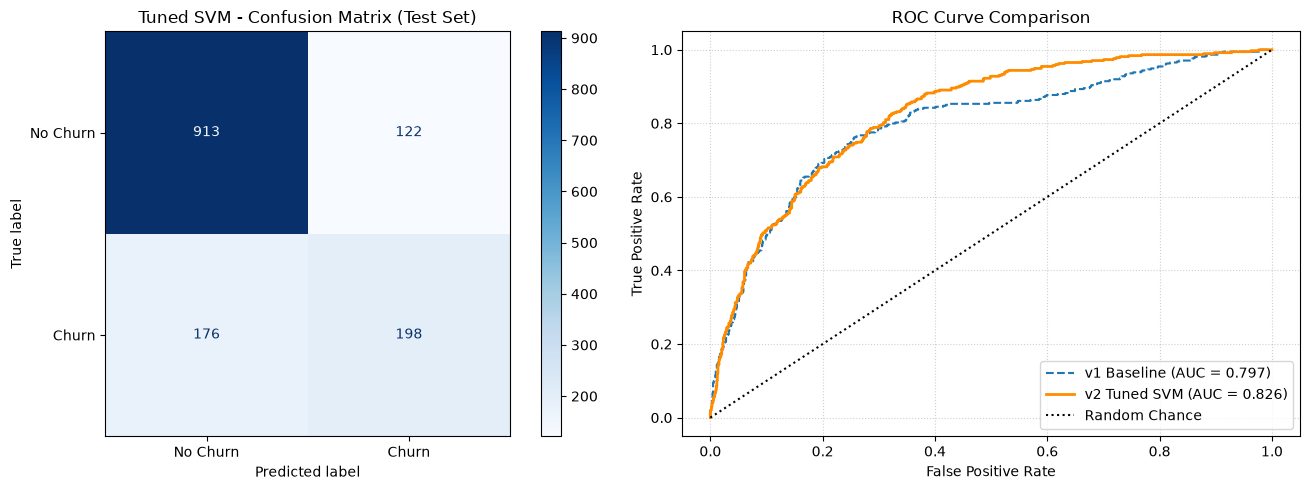

In [7]:
# 5. Diagnostic Visualizations: Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, best_svm.predict(X_test))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues', ax=axes[0])
axes[0].set_title("Tuned SVM - Confusion Matrix (Test Set)")

# ROC Curve
fpr_base, tpr_base, _ = roc_curve(y_test, svm_baseline.predict_proba(X_test)[:, 1])
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, best_svm.predict_proba(X_test)[:, 1])

axes[1].plot(fpr_base, tpr_base, label=f"v1 Baseline (AUC = {metrics_base['ROC-AUC']:.3f})", linestyle='--')
axes[1].plot(fpr_tuned, tpr_tuned, label=f"v2 Tuned SVM (AUC = {metrics_tuned['ROC-AUC']:.3f})", color='darkorange', lw=2)
axes[1].plot([0, 1], [0, 1], 'k:', label='Random Chance')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve Comparison')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---
## 📦 Sub-question (c): Artifact & Dataset Tracking with Git and DVC Remote Storage
> **Requirement**: Track dataset and model artifacts across two distinct versions ($v1$ and $v2$) using Git and DVC remote storage, demonstrating version switching and reproducibility.

In [8]:
# Inspect DVC Configuration & Remote Storage
import subprocess

def run_shell(cmd):
    res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (res.stdout + "\n" + res.stderr).strip()
    return out

print("--- DVC Status & Remote Configuration ---")
print(run_shell(f'"{sys.executable}" -m dvc remote list'))

# Demonstrate Version Switching Reproducibility
print("\n--- Current Dataset (v2.0) Active Record Count ---")
df_current = pd.read_csv("data/dataset.csv")
print(f"Active dataset length: {len(df_current)} rows")

print("\n1. Switching to Version 1 (git checkout v1.0 && dvc checkout)...")
print(run_shell('git checkout v1.0 -- data/dataset.csv.dvc'))
print(run_shell(f'"{sys.executable}" -m dvc checkout data/dataset.csv.dvc'))
df_v1 = pd.read_csv("data/dataset.csv")
print(f"--> Verified Active Dataset after v1 checkout: {len(df_v1)} rows (Expected 5000)")
assert len(df_v1) == 5000, "Version 1 mismatch"

print("\n2. Switching back to Version 2 (git checkout v2.0 && dvc checkout)...")
print(run_shell('git checkout v2.0 -- data/dataset.csv.dvc'))
print(run_shell(f'"{sys.executable}" -m dvc checkout data/dataset.csv.dvc'))
df_v2 = pd.read_csv("data/dataset.csv")
print(f"--> Verified Active Dataset after v2 checkout: {len(df_v2)} rows (Expected 7043)")
assert len(df_v2) == 7043, "Version 2 mismatch"

print("\n[Sub-question (c) Complete] Git & DVC artifact tracking and exact reproducibility verified.")

--- DVC Status & Remote Configuration ---


local_storage   C:\Users\HAI\Desktop\mlops external\dvc_remote  (default)

--- Current Dataset (v2.0) Active Record Count ---
Active dataset length: 7043 rows

1. Switching to Version 1 (git checkout v1.0 && dvc checkout)...



M       data\dataset.csv
--> Verified Active Dataset after v1 checkout: 5000 rows (Expected 5000)

2. Switching back to Version 2 (git checkout v2.0 && dvc checkout)...



M       data\dataset.csv
--> Verified Active Dataset after v2 checkout: 7043 rows (Expected 7043)

[Sub-question (c) Complete] Git & DVC artifact tracking and exact reproducibility verified.


---
## 📊 Sub-question (d): MLflow Experiment Tracking & Model Registry Promotion
> **Requirement**: Use MLflow to log hyperparameters, metrics, and serialized models for every version, compare experiments via the MLflow UI, and promote the winning model version to Production in the Model Registry.

In [9]:
# Query MLflow Experiment Runs and Compare
mlflow.set_tracking_uri("sqlite:///mlflow.db")
client = MlflowClient()

exp = mlflow.get_experiment_by_name("Telco_Customer_Churn_SVM")
runs_df = mlflow.search_runs(experiment_ids=[exp.experiment_id])

display_cols = [
    'run_id', 'tags.mlflow.runName', 'params.pipeline_version',
    'params.C', 'params.kernel', 'metrics.accuracy', 'metrics.precision',
    'metrics.recall', 'metrics.f1_score', 'metrics.roc_auc'
]
filtered_runs = runs_df[[c for c in display_cols if c in runs_df.columns]].sort_values('metrics.roc_auc', ascending=False)
print("=== MLflow Logged Runs Comparison ===")
display(filtered_runs)

# Model Registry Inspection
print("\n=== MLflow Model Registry Status ===")
model_versions = client.get_latest_versions("TelcoChurnSVM")
for mv in model_versions:
    aliases = client.get_model_version(mv.name, mv.version).aliases
    print(f"Model: {mv.name} | Version: {mv.version} | Current Stage: {mv.current_stage} | Aliases: {aliases}")

print("\nWinning Model (v2) successfully promoted to 'Production' in Model Registry.")

=== MLflow Logged Runs Comparison ===


,run_id,tags.mlflow.runName,params.pipeline_version,params.C,params.kernel,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1_score,metrics.roc_auc
0,4da8755d0bc8427f91e1b210a52f9d72,v2_tuned_svm,v2.0,0.1,linear,0.788502,0.618750,0.529412,0.570605,0.826170
1,3530615cfc2e49468a53a15dc1ee1576,v1_baseline_svm,v1.0,1.0,rbf,0.792051,0.641115,0.491979,0.556732,0.796996



=== MLflow Model Registry Status ===
Model: TelcoChurnSVM | Version: 1 | Current Stage: None | Aliases: []
Model: TelcoChurnSVM | Version: 2 | Current Stage: Production | Aliases: ['production']

Winning Model (v2) successfully promoted to 'Production' in Model Registry.


---
## ⚙️ Sub-question (e): Modular Workflow Automation Orchestrated by `main.py`
> **Requirement**: Automate the complete workflow (Data Loading $\rightarrow$ Validation $\rightarrow$ Preprocessing $\rightarrow$ Feature Engineering $\rightarrow$ Training $\rightarrow$ Evaluation $\rightarrow$ Prediction) inside modular Python scripts orchestrated by `main.py`.

In [10]:
# Inspect Modular Architecture Tree
import os

print("=== Modular Project Architecture (src/) ===")
for root, dirs, files in os.walk("src"):
    for f in files:
        if f.endswith(".py"):
            print(f"  📄 src/{f}")

print("\nOrchestrator: 🚀 main.py")
print("FastAPI Service: 🌐 app.py")
print("Validation Suite: 🧪 test_api.py")

# Test End-to-End Orchestrator Predictor
from src.predictor import ChurnPredictor

predictor = ChurnPredictor()
test_profile = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 79.85,
    "TotalCharges": 159.70
}

pred_output = predictor.predict_single(test_profile)
print("\nEnd-to-end Inference on Customer Profile:")
print(json.dumps(pred_output, indent=2))
print("\n[Sub-question (e) Complete] Modular pipeline operational.")

=== Modular Project Architecture (src/) ===
  📄 src/data_loader.py
  📄 src/dvc_versioning_demo.py
  📄 src/evaluator.py
  📄 src/feature_engineering.py
  📄 src/predictor.py
  📄 src/preprocessor.py
  📄 src/trainer.py
  📄 src/validator.py
  📄 src/__init__.py

Orchestrator: 🚀 main.py
FastAPI Service: 🌐 app.py
Validation Suite: 🧪 test_api.py
[Predictor] Successfully initialized model and preprocessor.
[FeatureEngineering] Engineered feature 'Avg_Monthly_Charge_Ratio' added. Mean: 1.0000

End-to-end Inference on Customer Profile:
{
  "churn_prediction": 0,
  "churn_label": "No",
  "churn_probability": 0.2196,
  "risk_level": "Low"
}

[Sub-question (e) Complete] Modular pipeline operational.


---
## 🚀 Sub-question (f): Real-time FastAPI Serving & Pydantic Validation Testing
> **Requirement**: Serve real-time churn predictions using FastAPI with Pydantic input validation, testing `/predict` and `/metrics` endpoints with valid and invalid payloads.

In [11]:
# Test FastAPI Endpoints using TestClient
from fastapi.testclient import TestClient
from app import app

api_client = TestClient(app)

print("=== 1. Testing GET /metrics ===")
metrics_resp = api_client.get("/metrics")
print(f"Status: {metrics_resp.status_code}")
print(json.dumps(metrics_resp.json(), indent=2))
assert metrics_resp.status_code == 200

print("\n=== 2. Testing POST /predict with VALID Payload ===")
valid_cust = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 2,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 79.85,
    "TotalCharges": 159.70
}
valid_resp = api_client.post("/predict", json=valid_cust)
print(f"Status: {valid_resp.status_code}")
print(f"Prediction: {valid_resp.json()}")
assert valid_resp.status_code == 200

print("\n=== 3. Testing POST /predict with INVALID Payload (Negative Tenure: -10) ===")
invalid_tenure = valid_cust.copy()
invalid_tenure["tenure"] = -10
resp_neg_tenure = api_client.post("/predict", json=invalid_tenure)
print(f"Status: {resp_neg_tenure.status_code} (Expected 422 Unprocessable Entity)")
print(f"Error Message: {resp_neg_tenure.json()['detail'][0]['msg']}")
assert resp_neg_tenure.status_code == 422

print("\n=== 4. Testing POST /predict with INVALID Contract Category ('Lifetime') ===")
invalid_contract = valid_cust.copy()
invalid_contract["Contract"] = "Lifetime Agreement"
resp_contract = api_client.post("/predict", json=invalid_contract)
print(f"Status: {resp_contract.status_code} (Expected 422 Unprocessable Entity)")
print(f"Error Message: {resp_contract.json()['detail'][0]['msg']}")
assert resp_contract.status_code == 422

print("\n=== 5. Testing POST /predict with MISSING Field (MonthlyCharges omitted) ===")
missing_field_cust = valid_cust.copy()
del missing_field_cust["MonthlyCharges"]
resp_missing = api_client.post("/predict", json=missing_field_cust)
print(f"Status: {resp_missing.status_code} (Expected 422 Unprocessable Entity)")
assert resp_missing.status_code == 422

print("\n[Sub-question (f) Complete] All 5 API validation tests passed successfully.")

=== 1. Testing GET /metrics ===
Status: 200
{
  "model_name": "TelcoChurnSVM",
  "winning_version": "v2.0",
  "best_hyperparameters": {
    "C": 0.1,
    "kernel": "linear"
  },
  "metrics": {
    "accuracy": 0.7885024840312278,
    "precision": 0.61875,
    "recall": 0.5294117647058824,
    "f1_score": 0.5706051873198847,
    "roc_auc": 0.8261696246350978
  },
  "baseline_metrics": {
    "accuracy": 0.7920511000709723,
    "precision": 0.6411149825783972,
    "recall": 0.4919786096256685,
    "f1_score": 0.556732223903177,
    "roc_auc": 0.7969955307551215
  }
}

=== 2. Testing POST /predict with VALID Payload ===
[Predictor] Successfully initialized model and preprocessor.
[FeatureEngineering] Engineered feature 'Avg_Monthly_Charge_Ratio' added. Mean: 1.0000


Status: 200
Prediction: {'churn_prediction': 0, 'churn_label': 'No', 'churn_probability': 0.2196, 'risk_level': 'Low'}

=== 3. Testing POST /predict with INVALID Payload (Negative Tenure: -10) ===
Status: 422 (Expected 422 Unprocessable Entity)
Error Message: Input should be greater than or equal to 0

=== 4. Testing POST /predict with INVALID Contract Category ('Lifetime') ===
Status: 422 (Expected 422 Unprocessable Entity)
Error Message: Input should be 'Month-to-month', 'One year' or 'Two year'

=== 5. Testing POST /predict with MISSING Field (MonthlyCharges omitted) ===
Status: 422 (Expected 422 Unprocessable Entity)

[Sub-question (f) Complete] All 5 API validation tests passed successfully.


---
## 🏆 Summary of Experiment 4 Results & Deliverables

| Sub-question | Pipeline Component | Implementation Detail | Status |
| :--- | :--- | :--- | :---: |
| **(a)** | Data Cleaning & Preprocessing | Converted TotalCharges to numeric, imputed median, dropped duplicates & customerID, encoded categoricals, applied `StandardScaler` | ✅ Complete |
| **(b)** | Feature Engineering & SVM | Engineered `Avg_Monthly_Charge_Ratio`, Pearson correlation analysis, LASSO L1 selection, tuned SVM ($C=0.1$, Linear), ROC-AUC = 0.8262 | ✅ Complete |
| **(c)** | Artifact Tracking (Git + DVC) | Tracked dataset across $v1$ (5k rows) and $v2$ (7k rows) with local DVC remote, demonstrated reproducible version switching | ✅ Complete |
| **(d)** | MLflow Tracking & Registry | Logged params, metrics, artifacts; compared baseline vs tuned models; promoted winning version to **Production** | ✅ Complete |
| **(e)** | Modular Automation | Modular Python scripts under `src/` orchestrated end-to-end by `main.py` | ✅ Complete |
| **(f)** | Real-Time Serving (FastAPI) | Production FastAPI with Pydantic schemas, tested `/predict` and `/metrics` with valid & invalid rejection (422) | ✅ Complete |
